
# Uczenie maszynowe — zajęcia 3
## Support Vector Machines — część 1: liniowy SVM od podstaw

**Uniwersytet Warmińsko-Mazurski w Olsztynie**  
**Semestr 5, rok akademicki 2026/2027**  
**Prowadzący: mgr inż. Adrian Albrecht**

---

## Cel zajęć

Na tych zajęciach rozpoczynamy pracę z **Support Vector Machines**.

Nie zaczynamy od gotowego `SVC.fit()`. Najpierw chcemy zrozumieć, **co liniowy SVM faktycznie optymalizuje** i przygotować się do napisania własnej implementacji `MyLinearSVM`.

Po zajęciach osoba studiująca powinna umieć:

1. wyjaśnić, czym jest liniowa hiperpłaszczyzna decyzyjna,
2. wyjaśnić rolę wektora wag i wyrazu wolnego,
3. wyjaśnić pojęcie marginesu,
4. wskazać, czym są wektory wspierające,
5. odróżnić hard margin od soft margin,
6. wyjaśnić sens parametru `C`,
7. wyjaśnić działanie hinge loss,
8. zapisać funkcję celu liniowego SVM,
9. rozpocząć własną implementację klasy `MyLinearSVM`.

> **Ważne:** właściwa implementacja `MyLinearSVM` jest zadaniem samodzielnym. Rozwiązania nie ma w tym notebooku.



## Plan zajęć — 90 minut

| Czas | Temat |
|---:|---|
| 0–10 min | Problem klasyfikacji liniowej |
| 10–25 min | Hiperpłaszczyzna i funkcja decyzyjna |
| 25–40 min | Margines i wektory wspierające |
| 40–55 min | Hard margin i jego ograniczenia |
| 55–70 min | Soft margin, hinge loss i parametr `C` |
| 70–82 min | Funkcja celu i schemat uczenia |
| 82–90 min | Omówienie `MyLinearSVM` i rozpoczęcie zadania |



# 0. Przygotowanie środowiska

Na zajęciach wykorzystamy:

- `numpy`,
- `pandas`,
- `matplotlib`,
- `sklearn.datasets.make_blobs` — wyłącznie do wygenerowania prostych danych.

Gotowego SVM nie potrzebujemy do właściwej części zajęć.


In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs

np.set_printoptions(precision=4, suppress=True)

RANDOM_STATE = 42



# 1. Problem klasyfikacji liniowej

Wygenerujmy prosty problem dwóch klas w przestrzeni dwuwymiarowej.


In [28]:

X, y_01 = make_blobs(
    n_samples=60,
    centers=[(-2.5, -2.0), (2.5, 2.0)],
    cluster_std=0.9,
    random_state=RANDOM_STATE
)

# Dla wygody w SVM klasy kodujemy jako -1 i 1
y = np.where(y_01 == 0, -1, 1)

print("Kształt X:", X.shape)
print("Unikalne klasy:", np.unique(y))


Kształt X: (60, 2)
Unikalne klasy: [-1  1]


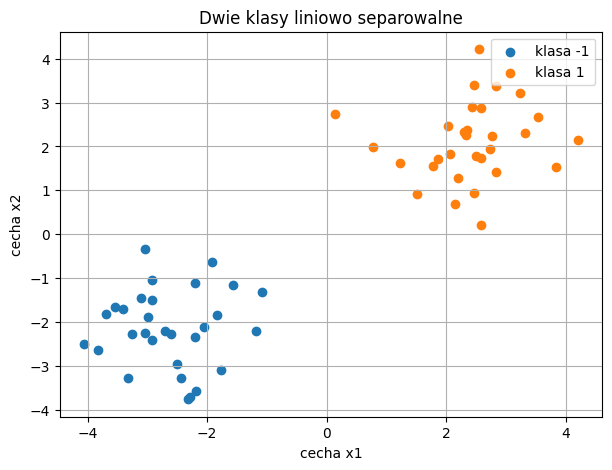

In [29]:

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask = y == class_id

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        label=f"klasa {class_id}"
    )

plt.xlabel("cecha x1")
plt.ylabel("cecha x2")
plt.title("Dwie klasy liniowo separowalne")
plt.legend()
plt.grid()
plt.show()



### Pytanie do grupy

Na wykresie można narysować wiele prostych, które poprawnie rozdzielą obie klasy.

Czy każda z nich jest równie dobra?

SVM odpowiada:

> **nie szukamy dowolnej poprawnej granicy — szukamy granicy z możliwie szerokim marginesem.**



# 2. Hiperpłaszczyzna decyzyjna

Liniową granicę decyzyjną zapisujemy jako:

$$
\mathbf{w}^T\mathbf{x}+b=0
$$

Dla dwóch cech:

$$
w_1x_1+w_2x_2+b=0
$$

gdzie:

- `x` — obserwacja,
- `w` — wektor wag,
- `b` — wyraz wolny.

W dwóch wymiarach granica jest prostą.  
W trzech — płaszczyzną.  
W większej liczbie wymiarów — hiperpłaszczyzną.



## 2.1. Funkcja decyzyjna

Dla dowolnego punktu możemy obliczyć:

$$
f(\mathbf{x})=
\mathbf{w}^T\mathbf{x}+b
$$

W najprostszym przypadku:

$$
f(\mathbf{x})>0
$$

oznacza klasę `+1`, a:

$$
f(\mathbf{x})<0
$$

oznacza klasę `-1`.

Granica decyzyjna spełnia:

$$
f(\mathbf{x})=0
$$


In [30]:

# Przykładowa ręcznie dobrana granica.
# To NIE jest jeszcze SVM.

w_example = np.array([1.0, 1.0])
b_example = 0.0

decision_values = X @ w_example + b_example

pred_example = np.where(
    decision_values >= 0,
    1,
    -1
)

preview = pd.DataFrame({
    "x1": X[:10, 0],
    "x2": X[:10, 1],
    "f(x)": decision_values[:10],
    "klasa": y[:10],
    "predykcja": pred_example[:10]
})

display(preview)


,x1,x2,f(x),klasa,predykcja
0,3.323862,2.295876,5.619738,1,1
1,-3.109230,-1.449491,-4.558721,-1,-1
2,2.554207,4.216918,6.771125,1,1
3,-1.078708,-1.309309,-2.388017,-1,-1
4,2.587370,2.871780,5.459150,1,1
5,2.731795,1.932999,4.664794,1,1
6,-1.835380,-1.845769,-3.681149,-1,-1
7,-3.040575,-2.262524,-5.303099,-1,-1
8,1.868152,1.705104,3.573256,1,1
9,2.302295,2.321401,4.623697,1,1



## 2.2. Jak narysować hiperpłaszczyznę w 2D?

Z równania:

$$
w_1x_1+w_2x_2+b=0
$$

otrzymujemy:

$$
x_2=
-\frac{w_1}{w_2}x_1
-\frac{b}{w_2}
$$


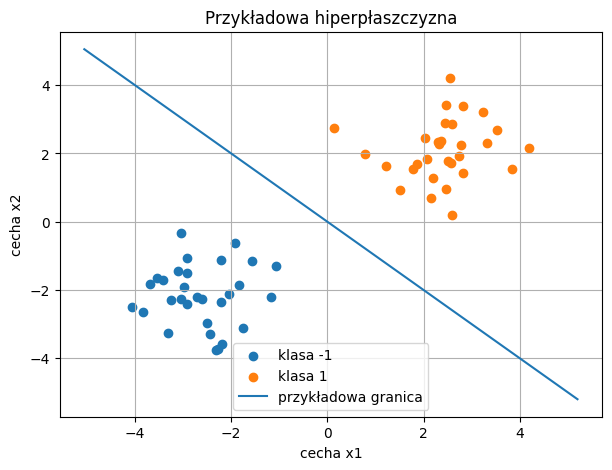

In [31]:

x_axis = np.linspace(
    X[:, 0].min() - 1,
    X[:, 0].max() + 1,
    200
)

y_axis = (
    -(w_example[0] / w_example[1]) * x_axis
    - b_example / w_example[1]
)

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask = y == class_id
    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        label=f"klasa {class_id}"
    )

plt.plot(
    x_axis,
    y_axis,
    label="przykładowa granica"
)

plt.xlabel("cecha x1")
plt.ylabel("cecha x2")
plt.title("Przykładowa hiperpłaszczyzna")
plt.legend()
plt.grid()
plt.show()



# 3. Dlaczego sama poprawna separacja nie wystarcza?

Dla danych liniowo separowalnych może istnieć bardzo wiele poprawnych granic.

SVM wybiera granicę, która maksymalizuje odległość od najbliższych obserwacji obu klas.

Tę odległość nazywamy **marginesem**.


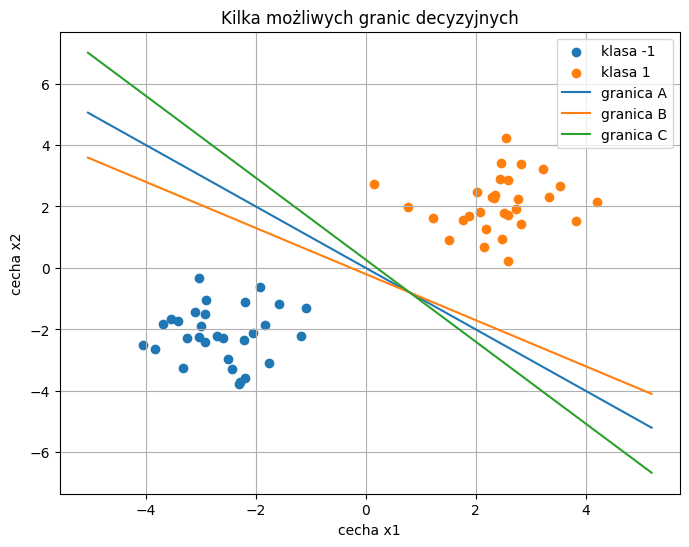

In [32]:

candidate_boundaries = [
    (np.array([1.0, 1.0]), 0.0, "granica A"),
    (np.array([0.75, 1.0]), 0.2, "granica B"),
    (np.array([1.0, 0.75]), -0.2, "granica C")
]

plt.figure(figsize=(8, 6))

for class_id in [-1, 1]:
    mask = y == class_id
    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        label=f"klasa {class_id}"
    )

x_axis = np.linspace(
    X[:, 0].min() - 1,
    X[:, 0].max() + 1,
    200
)

for w_tmp, b_tmp, label in candidate_boundaries:
    line = (
        -(w_tmp[0] / w_tmp[1]) * x_axis
        - b_tmp / w_tmp[1]
    )
    plt.plot(x_axis, line, label=label)

plt.xlabel("cecha x1")
plt.ylabel("cecha x2")
plt.title("Kilka możliwych granic decyzyjnych")
plt.legend()
plt.grid()
plt.show()



# 4. Margines

Geometryczna odległość punktu od hiperpłaszczyzny wynosi:

$$
d=
\frac{
\left|
\mathbf{w}^T\mathbf{x}+b
\right|
}{
\left\|\mathbf{w}\right\|
}
$$

W klasycznej normalizacji SVM dwie granice marginesu zapisujemy jako:

$$
\mathbf{w}^T\mathbf{x}+b=1
$$

oraz:

$$
\mathbf{w}^T\mathbf{x}+b=-1
$$

Szerokość całego marginesu wynosi:

$$
\frac{2}{\left\|\mathbf{w}\right\|}
$$

Czyli:

> im mniejsza norma wektora `w`, tym szerszy margines.



# 5. Wektory wspierające

Punkty znajdujące się najbliżej granicy decyzyjnej są najważniejsze dla wyznaczenia rozwiązania.

Nazywamy je **wektorami wspierającymi**.

Dla idealnego przypadku część z nich leży dokładnie na:

$$
\mathbf{w}^T\mathbf{x}+b=1
$$

lub:

$$
\mathbf{w}^T\mathbf{x}+b=-1
$$

Punkty położone bardzo daleko od marginesu zwykle nie wpływają bezpośrednio na jego położenie.

### Intuicja

Jeżeli przesuniemy punkt bardzo daleko od granicy, rozwiązanie może się nie zmienić.

Jeżeli przesuniemy wektor wspierający, granica może przesunąć się razem z nim.



# 6. Hard margin

Dla idealnie liniowo separowalnych danych chcemy spełnić:

$$
y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\geq 1
$$

dla każdej obserwacji.

Jednocześnie maksymalizujemy margines, czyli minimalizujemy:

$$
\frac{1}{2}
\left\|\mathbf{w}\right\|^2
$$

Otrzymujemy problem:

$$
\min_{\mathbf{w},b}
\frac{1}{2}
\left\|\mathbf{w}\right\|^2
$$

przy ograniczeniach:

$$
y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\geq 1
$$

To jest idea **hard-margin SVM**.



## 6.1. Problem hard margin

Co się stanie, jeśli:

- klasy częściowo na siebie nachodzą,
- jedna obserwacja jest odstająca,
- występuje szum,
- danych nie da się idealnie rozdzielić prostą?

Wtedy wymaganie:

$$
y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\geq 1
$$

dla wszystkich punktów może być niemożliwe.

Potrzebujemy modelu, który dopuszcza pewne naruszenia.


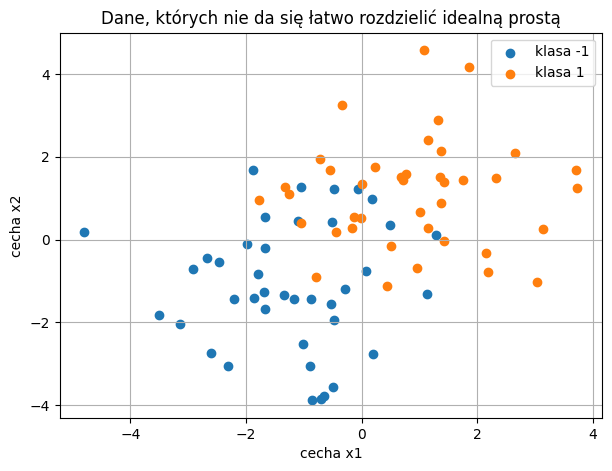

In [33]:

X_overlap, y_overlap_01 = make_blobs(
    n_samples=80,
    centers=[(-1.0, -1.0), (1.0, 1.0)],
    cluster_std=1.45,
    random_state=RANDOM_STATE
)

y_overlap = np.where(
    y_overlap_01 == 0,
    -1,
    1
)

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask = y_overlap == class_id
    plt.scatter(
        X_overlap[mask, 0],
        X_overlap[mask, 1],
        label=f"klasa {class_id}"
    )

plt.xlabel("cecha x1")
plt.ylabel("cecha x2")
plt.title("Dane, których nie da się łatwo rozdzielić idealną prostą")
plt.legend()
plt.grid()
plt.show()



# 7. Hinge loss

Dla pojedynczej obserwacji definiujemy:

$$
L_i=
\max
\left(
0,
1-y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\right)
$$

To **hinge loss**.

Rozważmy dwie sytuacje.

### Przypadek A

Jeżeli:

$$
y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\geq 1
$$

to:

$$
L_i=0
$$

Punkt znajduje się po poprawnej stronie marginesu.

### Przypadek B

Jeżeli:

$$
y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
<1
$$

to:

$$
L_i>0
$$

Punkt narusza margines albo znajduje się po niewłaściwej stronie granicy.


In [34]:

def hinge_loss_single(y_true, decision_value):
    return max(
        0.0,
        1.0 - y_true * decision_value
    )

examples = [
    (1, 2.0),
    (1, 0.6),
    (1, -0.5),
    (-1, -2.0),
    (-1, -0.4),
    (-1, 0.5)
]

rows = []

for y_true, decision_value in examples:
    rows.append({
        "y": y_true,
        "f(x)": decision_value,
        "y*f(x)": y_true * decision_value,
        "hinge loss": hinge_loss_single(
            y_true,
            decision_value
        )
    })

display(pd.DataFrame(rows))


,y,f(x),y*f(x),hinge loss
0,1,2.0,2.0,0.0
1,1,0.6,0.6,0.4
2,1,-0.5,-0.5,1.5
3,-1,-2.0,2.0,0.0
4,-1,-0.4,0.4,0.6
5,-1,0.5,-0.5,1.5



## 7.1. Jak wygląda hinge loss?

Jeżeli oznaczymy:

$$
z=
y_i f(\mathbf{x}_i)
$$

to:

$$
L(z)=\max(0,1-z)
$$

Dla:

$$
z\geq 1
$$

strata wynosi zero.

Dla:

$$
z<1
$$

strata rośnie liniowo.


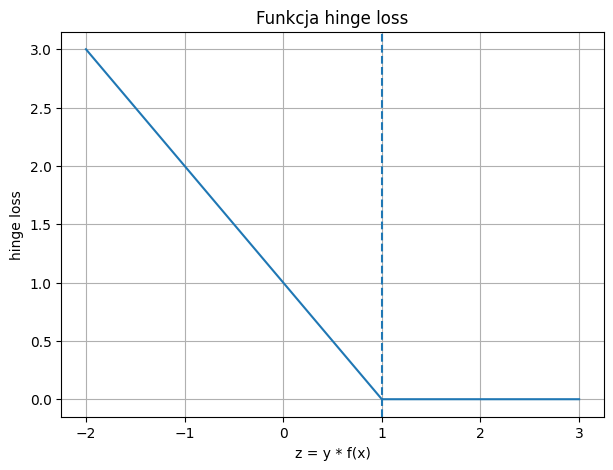

In [35]:

z = np.linspace(-2, 3, 400)

loss = np.maximum(
    0,
    1 - z
)

plt.figure(figsize=(7, 5))
plt.plot(z, loss)

plt.axvline(
    1,
    linestyle="--"
)

plt.xlabel("z = y * f(x)")
plt.ylabel("hinge loss")
plt.title("Funkcja hinge loss")
plt.grid()
plt.show()



# 8. Soft-margin SVM i parametr C

W praktyce chcemy jednocześnie:

1. mieć możliwie szeroki margines,
2. karać obserwacje naruszające margines.

Możemy więc zapisać funkcję celu:

$$
J(\mathbf{w},b)=
\frac{1}{2}
\left\|\mathbf{w}\right\|^2
+
C
\sum_{i=1}^{n}
\max
\left(
0,
1-y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\right)
$$

Pierwsza część:

$$
\frac{1}{2}
\left\|\mathbf{w}\right\|^2
$$

preferuje szeroki margines.

Druga część:

$$
C
\sum_i L_i
$$

karze naruszenia marginesu.



## 8.1. Znaczenie parametru C

`C` steruje kompromisem.

### Małe C

Naruszenia marginesu są relatywnie tanie.

Model może zaakceptować więcej naruszeń, aby zachować szerszy margines.

### Duże C

Naruszenia są mocno karane.

Model będzie mocniej próbował dopasować granicę do danych.

Nie oznacza to, że duże `C` jest zawsze lepsze.

`C` zmienia **zachowanie modelu**, a nie tylko „dokładność”.



# 9. Jak można uczyć taki model?

Mamy funkcję celu:

$$
J(\mathbf{w},b)=
\frac{1}{2}
\left\|\mathbf{w}\right\|^2
+
C
\sum_i
\max
\left(
0,
1-y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\right)
$$

Chcemy znaleźć takie `w` i `b`, dla których wartość tej funkcji będzie mała.

Jednym z prostych sposobów jest iteracyjna optymalizacja oparta na gradiencie lub subgradiencie.

Schemat uczenia może wyglądać następująco:

```text
zainicjalizuj w i b
        │
        ▼
powtarzaj przez określoną liczbę iteracji
        │
        ▼
dla każdej obserwacji oblicz:
y_i * (w^T x_i + b)
        │
        ▼
czy punkt spełnia warunek marginesu?
        │
        ├── TAK  → uwzględnij wpływ regularyzacji
        │
        └── NIE  → uwzględnij regularyzację i karę hinge loss
        │
        ▼
zaktualizuj parametry
```

Na tym etapie **nie dostajecie gotowych równań aktualizacji w kodzie**.

Ich poprawne przełożenie na implementację jest częścią zadania.



# 10. Funkcja celu — implementacja pomocnicza

Możemy jednak napisać funkcję, która dla zadanych parametrów `w` i `b` obliczy wartość celu.

Nie uczy ona modelu. Pozwala jedynie sprawdzić, czy podczas uczenia wartość funkcji celu rzeczywiście spada.


In [36]:

def svm_objective(X, y, w, b, C):
    decision = X @ w + b

    hinge = np.maximum(
        0,
        1 - y * decision
    )

    regularization = (
        0.5 * np.dot(w, w)
    )

    penalty = C * np.sum(hinge)

    return regularization + penalty


In [37]:

w_test = np.array([0.3, 0.4])
b_test = 0.0

print(
    "Przykładowa wartość funkcji celu:",
    svm_objective(
        X,
        y,
        w_test,
        b_test,
        C=1.0
    )
)


Przykładowa wartość funkcji celu: 0.9172901401475075


# 11. Demonstracja — własny `MyLinearSVM`

Celem demonstracji jest pokazanie, że opisany wyżej algorytm można samodzielnie zaimplementować bez `sklearn.svm.SVC`.

Po udostępnieniu notebooka bez pliku prowadzącego ta część nie zatrzyma wykonania całego materiału. Student powinien przygotować własny moduł o takim samym interfejsie.

In [38]:
try:
    from mySVM import MyLinearSVM
    HAS_MY_SVM = True
    print("Znaleziono implementację.")
except ImportError:
    HAS_MY_SVM = False
    print(
        "Brak modułu mySVM."
    )


Znaleziono implementację.


In [39]:
if HAS_MY_SVM:
    my_svm = MyLinearSVM(
        learning_rate=0.001,
        C=1.0,
        n_iterations=3000
    )

    my_svm.fit(X, y)
    predictions = my_svm.predict(X)

    print("w =", my_svm.w)
    print("b =", my_svm.b)
    print(
        "Poprawnie rozdzielone próbki:",
        np.sum(predictions == y),
        "/",
        len(y)
    )

w = [0.4417 0.3848]
b = -0.01963325173162947
Poprawnie rozdzielone próbki: 60 / 60


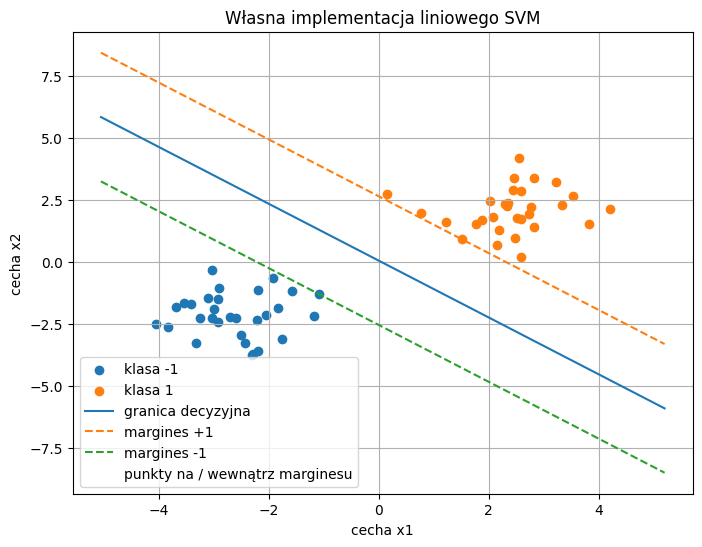

In [40]:
if HAS_MY_SVM:
    w = my_svm.w
    b = my_svm.b

    x_axis = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300)

    decision_boundary = -(w[0] / w[1]) * x_axis - b / w[1]
    margin_plus = -(w[0] / w[1]) * x_axis - (b - 1) / w[1]
    margin_minus = -(w[0] / w[1]) * x_axis - (b + 1) / w[1]

    plt.figure(figsize=(8, 6))

    for class_id in [-1, 1]:
        mask = y == class_id
        plt.scatter(X[mask, 0], X[mask, 1], label=f"klasa {class_id}")

    plt.plot(x_axis, decision_boundary, label="granica decyzyjna")
    plt.plot(x_axis, margin_plus, linestyle="--", label="margines +1")
    plt.plot(x_axis, margin_minus, linestyle="--", label="margines -1")

    if my_svm.support_vectors_ is not None and len(my_svm.support_vectors_) > 0:
        plt.scatter(
            my_svm.support_vectors_[:, 0],
            my_svm.support_vectors_[:, 1],
            s=170,
            facecolors="none",
            label="punkty na / wewnątrz marginesu"
        )

    plt.xlabel("cecha x1")
    plt.ylabel("cecha x2")
    plt.title("Własna implementacja liniowego SVM")
    plt.legend()
    plt.grid()
    plt.show()

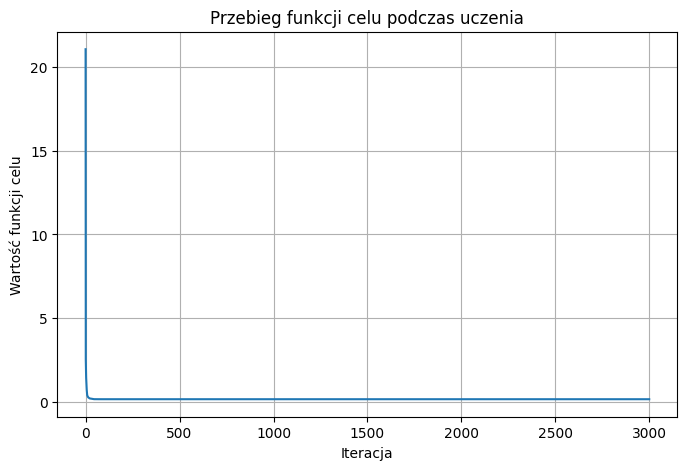

In [41]:
if HAS_MY_SVM:
    plt.figure(figsize=(8, 5))
    plt.plot(my_svm.loss_history_)
    plt.xlabel("Iteracja")
    plt.ylabel("Wartość funkcji celu")
    plt.title("Przebieg funkcji celu podczas uczenia")
    plt.grid()
    plt.show()


# 12. Zadanie — własny `MyLinearSVM`

Przygotuj **własny plik Python**, np.:

```text
mySVM.py
```

i zaimplementuj klasę:

```python
class MyLinearSVM:
    ...
```

## Minimalne wymagania

### 1. `fit(X, y)`

Metoda powinna:

- przyjąć macierz cech,
- przyjąć klasy zakodowane jako `-1` i `1`,
- zainicjalizować `w` i `b`,
- iteracyjnie modyfikować parametry,
- uwzględniać margines,
- uwzględniać hinge loss,
- uwzględniać parametr `C`.

### 2. `decision_function(X)`

Powinna zwracać wartość:

$$
\mathbf{w}^T\mathbf{x}+b
$$

dla każdej obserwacji.

### 3. `predict(X)`

Powinna zwracać:

$$
-1
$$

lub:

$$
1
$$

na podstawie znaku funkcji decyzyjnej.

### 4. Kontrola działania

Po implementacji należy sprawdzić model na prostych danych wygenerowanych przez `make_blobs`.

### 5. Dodatkowo

Jeżeli zapisujesz historię funkcji celu, możesz sprawdzić, czy podczas uczenia ma ona tendencję spadkową.

> **Nie chodzi wyłącznie o uzyskanie działającego kodu. Trzeba umieć wyjaśnić każdą część własnej implementacji.**


# 13. Jak sprawdzić własną implementację?

Po napisaniu klasy sprawdź:

1. Czy `w` ma tyle elementów, ile jest cech?
2. Czy `predict(X)` zwraca tyle etykiet, ile jest obserwacji?
3. Czy predykcje należą wyłącznie do `{-1, 1}`?
4. Czy `decision_function(X)` zwraca po jednej wartości na obserwację?
5. Czy model potrafi rozdzielić prosty zbiór liniowo separowalny?
6. Co dzieje się po zmianie `C`?
7. Co dzieje się po zmianie kroku uczenia?
8. Co dzieje się po zmianie liczby iteracji?
9. Jeżeli zapisujesz funkcję celu — czy ma ogólną tendencję malejącą?

Nie wystarczy, że kod działa. Trzeba umieć wyjaśnić **skąd wynika każda aktualizacja parametrów**.


# 14. Testy, które warto wykonać we własnej implementacji

Po napisaniu klasy sprawdź:

### Test 1

Czy po `fit()`:

```python
model.w
```

ma tyle elementów, ile danych jest cech?

### Test 2

Czy:

```python
model.predict(X)
```

zwraca tyle wartości, ile mamy obserwacji?

### Test 3

Czy przewidywane klasy należą wyłącznie do zbioru:

```text
{-1, 1}
```

### Test 4

Czy:

```python
model.decision_function(X)
```

zwraca jedną wartość dla każdej obserwacji?

### Test 5

Czy model potrafi rozdzielić prosty, wyraźnie liniowo separowalny zbiór?

### Test 6

Co dzieje się po zmianie `C`?

### Test 7

Co dzieje się po zmianie `learning_rate`?

### Test 8

Co dzieje się po zwiększeniu lub zmniejszeniu `n_iterations`?



# 15. Pytania podsumowujące

Po zajęciach powinieneś/powinnaś umieć odpowiedzieć na pytania:

1. Jak wygląda równanie liniowej hiperpłaszczyzny?
2. Co oznaczają `w` oraz `b`?
3. Co oznacza znak funkcji decyzyjnej?
4. Dlaczego nie każda poprawnie rozdzielająca prosta jest równie dobra?
5. Co oznacza margines?
6. Od czego zależy szerokość marginesu?
7. Czym są wektory wspierające?
8. Dlaczego punkty odległe od granicy mają mniejsze znaczenie?
9. Na czym polega hard-margin SVM?
10. Dlaczego hard margin nie zawsze może być zastosowany?
11. Co oznacza hinge loss?
12. Kiedy hinge loss wynosi zero?
13. Kiedy hinge loss jest dodatni?
14. Co oznacza parametr `C`?
15. Co stanie się intuicyjnie po zwiększeniu `C`?
16. Co zawiera funkcja celu soft-margin SVM?
17. Dlaczego funkcja celu zawiera jednocześnie normę `w` i hinge loss?
18. Co ma zwracać `decision_function()`?
19. W jaki sposób `predict()` może wykorzystać `decision_function()`?
20. Dlaczego własna implementacja będzie prostsza od `sklearn.svm.SVC`?



# 16. Najważniejsze wnioski

> **Liniowy SVM szuka hiperpłaszczyzny, która rozdziela klasy przy możliwie szerokim marginesie.**

> **O granicy w szczególności decydują obserwacje położone najbliżej niej — wektory wspierające.**

> **Soft-margin SVM pozwala świadomie zaakceptować część naruszeń marginesu.**

> **Hinge loss opisuje koszt obserwacji znajdujących się wewnątrz marginesu lub po niewłaściwej stronie granicy.**

> **Parametr `C` steruje kompromisem pomiędzy szerokim marginesem a karaniem naruszeń.**

Na następnych zajęciach wykorzystamy własną klasę `MyLinearSVM`, sprawdzimy jej zachowanie dla różnych wartości `C`, porównamy ją z liniowym `SVC`, a następnie przejdziemy do danych nieliniowych i funkcji jądra.
